<a href="https://colab.research.google.com/github/GOAT911/TP_ML/blob/main/TP1_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 : Prétraitement d'un dataset (Titanic)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [2]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(891, 15)
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [3]:
print((df.isnull().mean() * 100).round(1))

survived        0.0
pclass          0.0
sex             0.0
age            19.9
sibsp           0.0
parch           0.0
fare            0.0
embarked        0.2
class           0.0
who             0.0
adult_male      0.0
deck           77.2
embark_town     0.2
alive           0.0
alone           0.0
dtype: float64


In [4]:
df = df.drop(columns=["deck"])
print(df.shape)

(891, 14)


In [5]:
print("Médiane de l'âge :", df["age"].median())

df["age"] = df["age"].fillna(df["age"].median())

print("Manquants dans age :", df["age"].isnull().sum())

Médiane de l'âge : 28.0
Manquants dans age : 0


In [6]:
print("Mode de embarked :", df["embarked"].mode()[0])
print("Mode de embark_town :", df["embark_town"].mode()[0])

df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

print(df.isnull().sum())

Mode de embarked : S
Mode de embark_town : Southampton
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


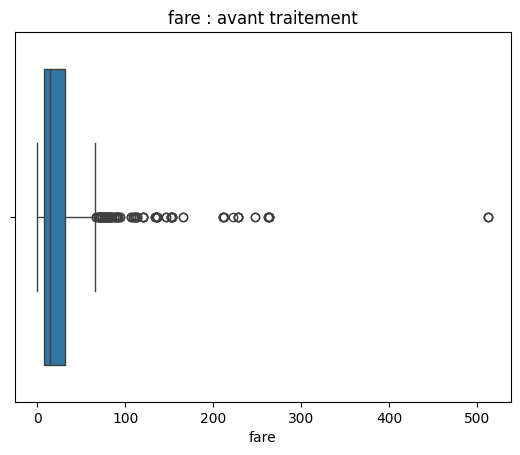

In [7]:
sns.boxplot(x=df["fare"])
plt.title("fare : avant traitement")
plt.show()

In [8]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
IQR = Q3 - Q1

limite_basse = Q1 - 1.5 * IQR
limite_haute = Q3 + 1.5 * IQR

aberrantes = (df["fare"] < limite_basse) | (df["fare"] > limite_haute)

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Limite basse :", limite_basse)
print("Limite haute :", limite_haute)
print("Nombre de valeurs aberrantes :", aberrantes.sum())

Q1 : 7.9104
Q3 : 31.0
IQR : 23.0896
Limite basse : -26.724
Limite haute : 65.6344
Nombre de valeurs aberrantes : 116


In [9]:
mediane_fare = df["fare"].median()
print("Médiane de fare :", mediane_fare)

df.loc[aberrantes, "fare"] = mediane_fare

print("Taille du tableau :", df.shape)
print("Max de fare maintenant :", df["fare"].max())

Médiane de fare : 14.4542
Taille du tableau : (891, 14)
Max de fare maintenant : 65.0


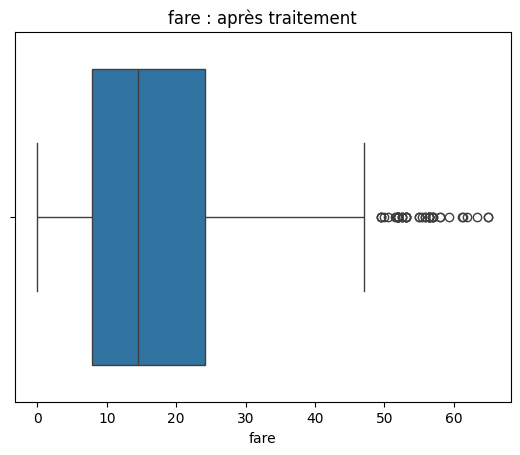

In [10]:
sns.boxplot(x=df["fare"])
plt.title("fare : après traitement")
plt.show()

In [11]:
print("AVANT :")
print(df[["sex", "embarked"]].head())

df = pd.get_dummies(df, columns=["sex", "embarked"], drop_first=True)

print("APRÈS :")
print(df.head())
print(df.shape)

AVANT :
      sex embarked
0    male        S
1  female        C
2  female        S
3  female        S
4    male        S
APRÈS :
   survived  pclass   age  sibsp  parch     fare  class    who  adult_male  \
0         0       3  22.0      1      0   7.2500  Third    man        True   
1         1       1  38.0      1      0  14.4542  First  woman       False   
2         1       3  26.0      0      0   7.9250  Third  woman       False   
3         1       1  35.0      1      0  53.1000  First  woman       False   
4         0       3  35.0      0      0   8.0500  Third    man        True   

   embark_town alive  alone  sex_male  embarked_Q  embarked_S  
0  Southampton    no  False      True       False        True  
1    Cherbourg   yes  False     False       False       False  
2  Southampton   yes   True     False       False        True  
3  Southampton   yes  False     False       False        True  
4  Southampton    no   True      True       False        True  
(891, 15)


In [12]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cols = ["age", "fare"]

df_minmax = df.copy()
df_minmax[cols] = MinMaxScaler().fit_transform(df[cols])

df_std = df.copy()
df_std[cols] = StandardScaler().fit_transform(df[cols])

print("Min-Max :")
print(df_minmax[cols].describe().loc[["min", "max"]])

print("Z-score :")
print(df_std[cols].describe().loc[["mean", "std"]])

Min-Max :
     age  fare
min  0.0   0.0
max  1.0   1.0
Z-score :
               age          fare
mean  2.272780e-16 -9.569599e-17
std   1.000562e+00  1.000562e+00


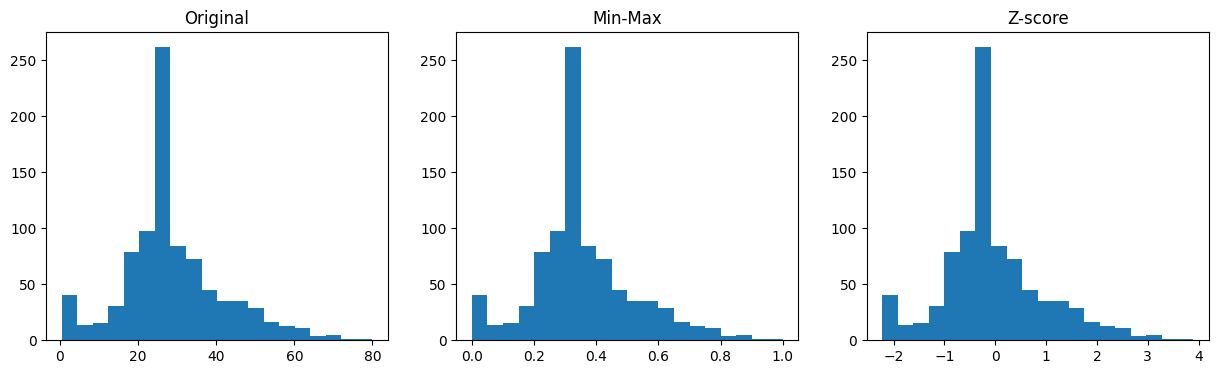

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(df["age"], bins=20)
ax[0].set_title("Original")

ax[1].hist(df_minmax["age"], bins=20)
ax[1].set_title("Min-Max")

ax[2].hist(df_std["age"], bins=20)
ax[2].set_title("Z-score")

plt.show()

In [14]:
print(df["survived"].value_counts())
print(df["survived"].value_counts(normalize=True).round(3))

survived
0    549
1    342
Name: count, dtype: int64
survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

X = df[["pclass", "age", "sibsp", "parch", "fare",
        "sex_male", "embarked_Q", "embarked_S"]].astype(float)
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :")
print(y_train.value_counts())

X_train : (712, 8)
X_test  : (179, 8)
y_train :
survived
0    439
1    273
Name: count, dtype: int64


In [16]:
!pip install imbalanced-learn -q

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

X_under, y_under = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

print("Avant         :", y_train.value_counts().to_dict())
print("Undersampling :", y_under.value_counts().to_dict())
print("SMOTE         :", y_smote.value_counts().to_dict())

Avant         : {0: 439, 1: 273}
Undersampling : {0: 273, 1: 273}
SMOTE         : {1: 439, 0: 439}


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

def evaluer(nom, Xt, yt):
    modele = LogisticRegression(max_iter=1000).fit(Xt, yt)
    pred = modele.predict(X_test)
    print(f"{nom:16} acc={accuracy_score(y_test, pred):.3f}  "
          f"precision={precision_score(y_test, pred):.3f}  "
          f"rappel={recall_score(y_test, pred):.3f}  "
          f"f1={f1_score(y_test, pred):.3f}")

evaluer("Sans resampling", X_train, y_train)
evaluer("Undersampling", X_under, y_under)
evaluer("SMOTE", X_smote, y_smote)

Sans resampling  acc=0.788  precision=0.738  rappel=0.696  f1=0.716
Undersampling    acc=0.804  precision=0.724  rappel=0.797  f1=0.759
SMOTE            acc=0.816  precision=0.743  rappel=0.797  f1=0.769
